# Ejercicio 3. Agrupamiento jerárquico del conjunto Iris

En este ejercicio se utilizará el conjunto de datos **Iris**, que contiene 150 muestras de flores descritas mediante cuatro variables: longitud y ancho del sépalo y del pétalo.

Se estandarizarán los datos y se construirá un **dendrograma** para explorar cómo se unen las observaciones y proponer un número de clústeres. Posteriormente, se aplicará agrupamiento jerárquico aglomerativo y se evaluarán e interpretarán los grupos obtenidos.

Las etiquetas originales de las especies no se utilizarán para construir los clústeres. Finalmente, se empleará PCA únicamente para visualizar el resultado en dos dimensiones.

## 1. Carga y revisión de los datos

Se carga el conjunto Iris y se almacenan sus cuatro variables predictoras en la tabla **X_iris**, sin incluir las etiquetas de especie.

Se revisan las primeras observaciones, los tipos de datos, los valores nulos y las estadísticas descriptivas para conocer la estructura y las escalas de las variables antes del agrupamiento.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Cargar Iris y conservar únicamente las variables predictoras.
iris = load_iris(as_frame=True)
X_iris = iris.data.copy()

print("Número de registros:", X_iris.shape[0])
print("Número de variables:", X_iris.shape[1])

display(X_iris.head())

# Consultar los tipos de datos y valores no nulos.
X_iris.info()

print("\nValores nulos por variable:")
display(X_iris.isnull().sum().to_frame(name="Valores nulos"))

print("\nEstadísticas descriptivas:")
display(X_iris.describe().T)

Número de registros: 150
Número de variables: 4


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB

Valores nulos por variable:


,Valores nulos
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 2. Estandarización de las variables

No se encontraron valores nulos, por lo que no es necesario imputar datos faltantes.

Aunque las cuatro variables están expresadas en centímetros, presentan diferentes rangos y dispersiones. Por ejemplo, la desviación estándar de la longitud del pétalo es aproximadamente 1,765 cm, mientras que la del ancho del sépalo es 0,436 cm.

Se aplica **StandardScaler** para equilibrar su contribución al cálculo de distancias. Los datos originales se conservan para interpretar posteriormente los grupos.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Estandarizar las cuatro variables de Iris.
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

# Conservar los nombres de las variables y el índice.
X_iris_scaled = pd.DataFrame(
    X_iris_scaled,
    columns=X_iris.columns,
    index=X_iris.index
)

# Verificar el resultado de la transformación.
verificacion_iris = pd.DataFrame({
    "Media": X_iris_scaled.mean(),
    "Desviación estándar": X_iris_scaled.std(ddof=0)
})

display(verificacion_iris.round(4))

,Media,Desviación estándar
sepal length (cm),-0.0,1.0
sepal width (cm),-0.0,1.0
petal length (cm),-0.0,1.0
petal width (cm),-0.0,1.0


## 3. Construcción del dendrograma

Se utiliza agrupamiento jerárquico aglomerativo con el método de **Ward** y distancia euclídea sobre los datos estandarizados.

El procedimiento comienza con cada observación como un grupo independiente. En cada etapa se unen los dos grupos cuya fusión produce el menor incremento de la variabilidad interna.

El dendrograma representa estas uniones. Las alturas indican el valor del criterio de enlace de Ward: las uniones más altas corresponden a fusiones entre grupos más diferentes. Se examinarán los saltos entre las últimas fusiones para proponer un punto de corte y un número de clústeres.

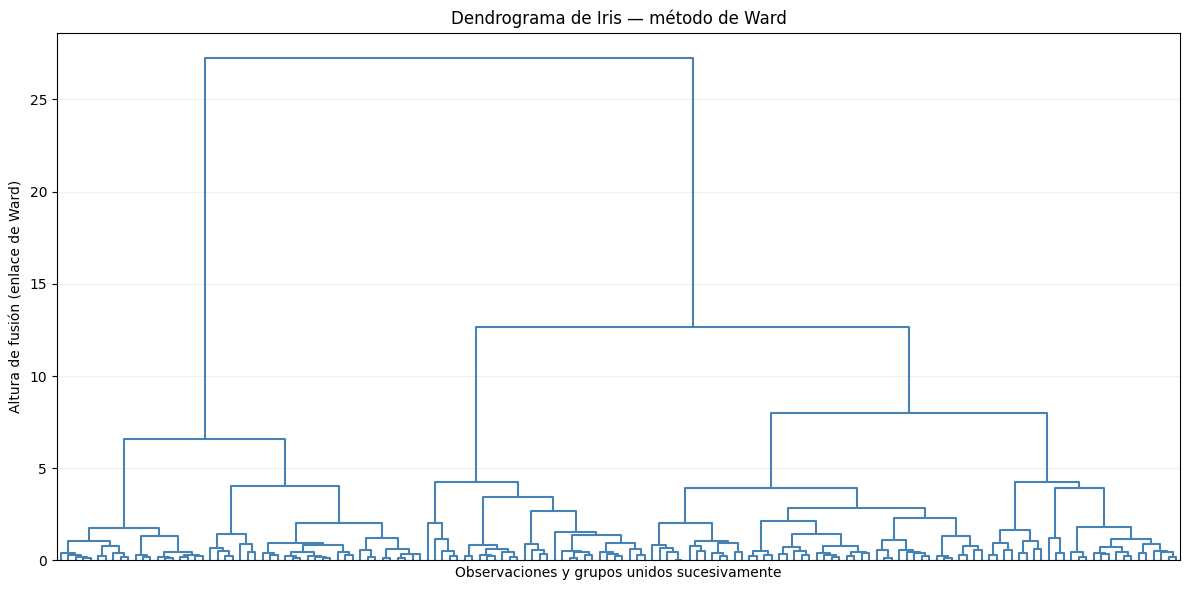

Alturas de las últimas cinco fusiones:
[ 4.243  6.608  8.005 12.637 27.25 ]


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Calcular las fusiones con Ward y distancia euclídea.
enlaces_iris = linkage(
    X_iris_scaled,
    method="ward",
    metric="euclidean"
)

# Mostrar el dendrograma completo sin las etiquetas individuales.
fig, ax = plt.subplots(figsize=(12, 6))

dendrogram(
    enlaces_iris,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="steelblue",
    ax=ax
)

ax.set_title("Dendrograma de Iris — método de Ward")
ax.set_xlabel("Observaciones y grupos unidos sucesivamente")
ax.set_ylabel("Altura de fusión (enlace de Ward)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Consultar las alturas de las últimas cinco fusiones.
print("Alturas de las últimas cinco fusiones:")
print(enlaces_iris[-5:, 2].round(3))

## 4. Selección del corte y construcción del modelo

Se propone un corte a una altura de **20**, situado entre las dos últimas fusiones del dendrograma, aproximadamente en 12,7 y 27. Este intervalo presenta el mayor salto entre fusiones consecutivas y permite conservar dos grupos antes de unirlos en uno solo.

Por esta

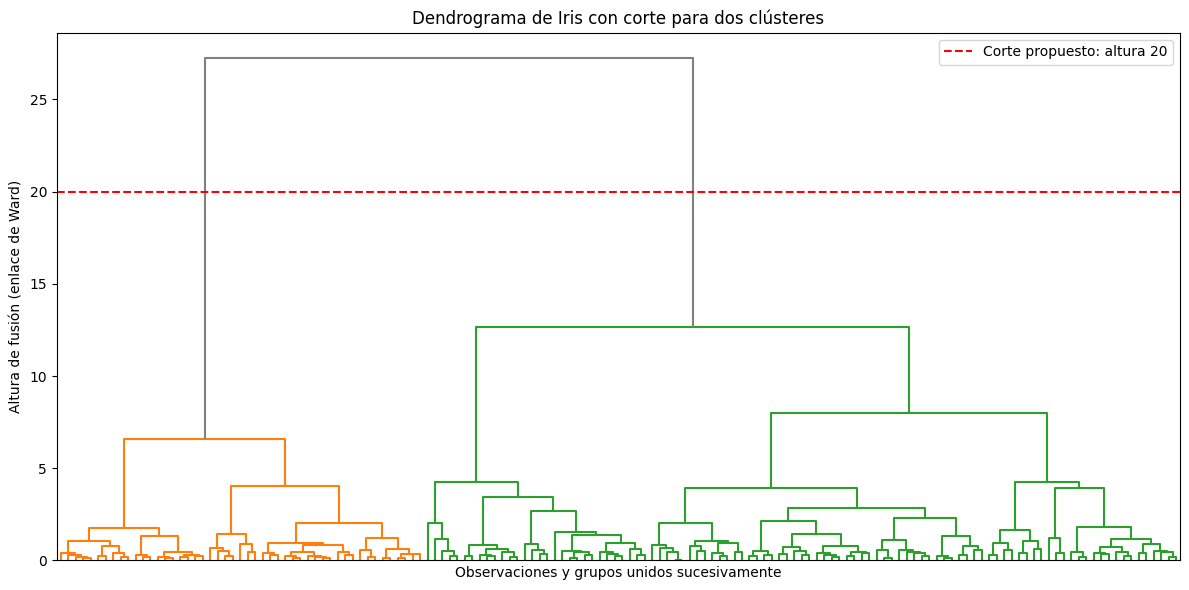

,Número de muestras
Clúster,
0,101
1,49


In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Señalar el corte propuesto en el dendrograma.
fig, ax = plt.subplots(figsize=(12, 6))

dendrogram(
    enlaces_iris,
    no_labels=True,
    color_threshold=20,
    above_threshold_color="gray",
    ax=ax
)

ax.axhline(
    y=20, color="red", linestyle="--",
    label="Corte propuesto: altura 20"
)
ax.set_title("Dendrograma de Iris con corte para dos clústeres")
ax.set_xlabel("Observaciones y grupos unidos sucesivamente")
ax.set_ylabel("Altura de fusión (enlace de Ward)")
ax.legend()

plt.tight_layout()
plt.show()

# Construir dos grupos con el mismo método de enlace.
modelo_jerarquico = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)
clusters_iris = modelo_jerarquico.fit_predict(X_iris_scaled)

# Contar las observaciones asignadas a cada grupo.
tamanos_iris = (
    pd.Series(clusters_iris, name="Clúster")
    .value_counts()
    .sort_index()
    .to_frame(name="Número de muestras")
)

display(tamanos_iris)

## 5. Evaluación del agrupamiento jerárquico

El modelo distribuyó las 150 observaciones en dos clústeres, con 101 y 49 muestras respectivamente.

Se calculan tres métricas sobre las cuatro variables estandarizadas:

- **Silhouette:** evalúa la cohesión y separación de los grupos; los valores más cercanos a 1 indican una mejor separación.
- **Davies-Bouldin:** relaciona la dispersión interna con la separación entre grupos; los valores menores son preferibles.
- **Calinski-Harabasz:** relaciona la dispersión entre grupos con la dispersión interna; los valores mayores son preferibles.

Las métricas se interpretarán junto con el dendrograma y la visualización. No se compararán directamente con las de Wine y las medias lunas para decidir qué algoritmo es mejor, porque se utilizaron conjuntos de datos diferentes.

In [ ]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Evaluar los grupos en las cuatro dimensiones estandarizadas.
metricas_jerarquico = pd.DataFrame([{
    "Clústeres": len(set(clusters_iris)),
    "Silhouette": silhouette_score(X_iris_scaled, clusters_iris),
    "Davies-Bouldin": davies_bouldin_score(
        X_iris_scaled, clusters_iris
    ),
    "Calinski-Harabasz": calinski_harabasz_score(
        X_iris_scaled, clusters_iris
    )
}])

display(metricas_jerarquico.round(4))

,Clústeres,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.577,0.5917,240.2457


## 6. Visualización de los clústeres mediante PCA

Se aplica **PCA con dos componentes** para representar gráficamente las observaciones y los grupos asignados por el modelo jerárquico.

PCA se utiliza únicamente para visualizar. El agrupamiento y las métricas se calcularon previamente con las cuatro variables estandarizadas. Los ejes muestran el porcentaje de varianza explicado por cada componente, lo que permite conocer cuánta información conserva la proyección.

Varianza explicada por los dos componentes: 95.81%


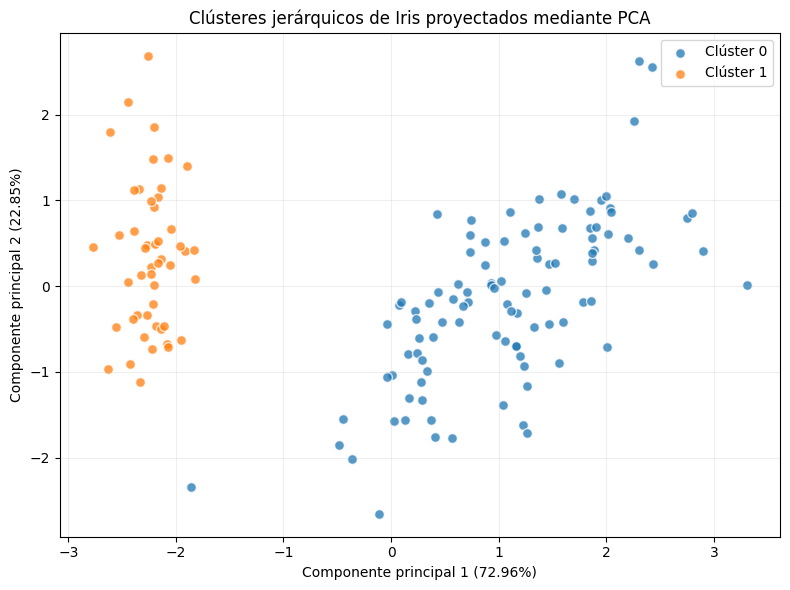

In [ ]:
from sklearn.decomposition import PCA

# Proyectar las cuatro variables estandarizadas en dos dimensiones.
pca_iris = PCA(n_components=2, svd_solver="full")
X_iris_pca = pca_iris.fit_transform(X_iris_scaled)

varianza_iris = pca_iris.explained_variance_ratio_ * 100
print(
    "Varianza explicada por los dos componentes: "
    f"{varianza_iris.sum():.2f}%"
)

# Visualizar las etiquetas obtenidas con el modelo jerárquico.
fig, ax = plt.subplots(figsize=(8, 6))
colores = ["tab:blue", "tab:orange"]

for grupo, color in enumerate(colores):
    seleccion = clusters_iris == grupo

    ax.scatter(
        X_iris_pca[seleccion, 0],
        X_iris_pca[seleccion, 1],
        color=color,
        label=f"Clúster {grupo}",
        alpha=0.75,
        edgecolors="white",
        s=50
    )

ax.set_title("Clústeres jerárquicos de Iris proyectados mediante PCA")
ax.set_xlabel(f"Componente principal 1 ({varianza_iris[0]:.2f}%)")
ax.set_ylabel(f"Componente principal 2 ({varianza_iris[1]:.2f}%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 7. Caracterización de los grupos

Los dos primeros componentes principales explican el **95,81 % de la varianza total**, por lo que la proyección conserva gran parte de la variabilidad de los datos estandarizados. Se observa una separación entre los grupos principalmente sobre el primer componente, aunque no es perfecta.

Se calculan los promedios de las cuatro variables originales por clúster para describir las diferencias en las dimensiones de pétalos y sépalos. Los valores se expresan en centímetros.

Los identificadores de los clústeres no equivalen a etiquetas de especie, ya que estas no se utilizaron durante el agrupamiento.



In [ ]:
# Añadir las etiquetas a una copia de los datos originales.
datos_iris_clusters = X_iris.copy()
datos_iris_clusters["Cluster"] = clusters_iris

# Calcular las medias de las variables originales por grupo.
perfiles_iris = (
    datos_iris_clusters
    .groupby("Cluster")[X_iris.columns]
    .mean()
)

print("Promedios por clúster, en centímetros:")
display(perfiles_iris.T.round(3))

Promedios por clúster, en centímetros:


Cluster,0,1
sepal length (cm),6.245,5.016
sepal width (cm),2.866,3.451
petal length (cm),4.870,1.465
petal width (cm),1.662,0.245


## 8. Interpretación de los resultados y conclusiones

El agrupamiento jerárquico con enlace de Ward identificó dos grupos con perfiles diferentes:

- **Clúster 0 — 101 muestras:** presenta sépalos de 6,245 cm de longitud y 2,866 cm de ancho, y pétalos de 4,870 cm de longitud y 1,662 cm de ancho, en promedio.
- **Clúster 1 — 49 muestras:** presenta sépalos de 5,016 cm de longitud y 3,451 cm de ancho, y pétalos de 1,465 cm de longitud y 0,245 cm de ancho, en promedio.

Las diferencias más marcadas en centímetros se observan en las dimensiones de los pétalos. El clúster 0 reúne flores con pétalos más largos y anchos y sépalos más largos; el clúster 1 presenta pétalos más pequeños y sépalos más anchos.

### Interpretación del dendrograma y del corte

El dendrograma muestra el orden y las alturas a las que se fusionan las observaciones y los grupos. El mayor salto entre las últimas fusiones se encuentra aproximadamente entre 12,7 y 27. Por ello, se propuso un corte a una altura de 20, que conserva dos clústeres.

Esta elección representa una división amplia de los datos. Otros cortes permitirían explorar subgrupos, sin que sea necesario imponer el número de especies conocidas.

### Separación de los grupos

El Silhouette Score de **0,577** respalda una separación apreciable, aunque no perfecta. Los valores de Davies-Bouldin y Calinski-Harabasz fueron **0,5917** y **240,2457**, respectivamente.

La proyección PCA conserva el **95,81 % de la varianza** y muestra una separación visual principalmente sobre el primer componente. El clúster 0 presenta mayor dispersión en esta representación.

### Diferencias frente a K-Means

K-Means ajusta centroides y reasigna observaciones para reducir las distancias cuadráticas dentro de los grupos. El método jerárquico aglomerativo comienza con observaciones individuales y fusiona grupos sucesivamente; las fusiones realizadas no se deshacen.

El dendrograma permite examinar distintos niveles de agrupamiento antes de seleccionar una partición. Sin embargo, el resultado depende de la estandarización, la distancia y el método de enlace. Ward, al igual que K-Means, favorece agrupamientos compactos.

### Conclusión

El procedimiento permitió identificar dos perfiles de flores diferenciados principalmente por las dimensiones de sus pétalos. La elección del número de clústeres se fundamentó en el dendrograma y se complementó con métricas y visualización.

La representación jerárquica facilita explorar relaciones entre grupos y posibles subgrupos. Sus limitaciones incluyen la sensibilidad a valores atípicos y a las decisiones de preprocesamiento y enlace, además de un mayor costo de cálculo al aumentar el número de observaciones.

# Comparación de los algoritmos de clustering

Los algoritmos se aplicaron a conjuntos de datos diferentes. Por tanto, las métricas describen cada resultado, pero **no permiten establecer cuál algoritmo es mejor** mediante una comparación directa.

| Aspecto | K-Means | DBSCAN | Clustering jerárquico |
|---|---|---|---|
| Dataset | Wine | Dos medias lunas | Iris |
| Construcción de grupos | Asigna observaciones a centroides y los actualiza | Conecta regiones densas mediante puntos núcleo | Fusiona grupos sucesivamente mediante enlace de Ward |
| Número de clústeres obtenido | 3 | 2 | 2 |
| Hiperparámetros principales | K = 3, n_init = 10, random_state = 42 | eps = 0,30; min_samples = 5; distancia euclídea | n_clusters = 2; enlace Ward; distancia euclídea |
| Silhouette Score | 0,2849 | 0,3857 | 0,5770 |
| Davies-Bouldin Index | 1,3892 | 1,0215 | 0,5917 |
| Calinski-Harabasz Score | 70,9400 | 433,8817 | 240,2457 |
| Identifica ruido explícitamente | No | Sí; no detectó ruido con la configuración seleccionada | No |
| Requiere definir previamente el número de clústeres | Sí | No | No para construir el dendrograma; sí al configurar la partición final con n_clusters |
| Principal ventaja | Es eficiente para segmentar datos en grupos compactos | Reconoce formas curvas y permite detectar ruido | Permite explorar relaciones entre grupos a distintos niveles |
| Principal limitación | Puede representar mal grupos con formas complejas | Es sensible a los parámetros y a diferencias de densidad | Las fusiones son irreversibles y el cálculo puede ser costoso en conjuntos grandes |

## ¿En qué tipo de problema utilizaría cada algoritmo?

Utilizaría **K-Means** para segmentar observaciones con características numéricas cuando busque grupos compactos y pueda evaluar un número razonable de clústeres, por ejemplo, al agrupar clientes según sus hábitos de compra.

Utilizaría **DBSCAN** cuando espere grupos con formas irregulares y necesite identificar observaciones aisladas, por ejemplo, al explorar concentraciones geográficas. Revisaría especialmente la escala de las variables y las diferencias de densidad.

Utilizaría **clustering jerárquico** en conjuntos pequeños o medianos cuando me interese explorar cómo se relacionan las observaciones y sus subgrupos, por ejemplo, al comparar perfiles de muestras biológicas.

En los tres casos, elegiría el método considerando la estructura de los datos, el objetivo del análisis y la interpretación conjunta de métricas y visualizaciones.

## Versiones del entorno de ejecución

Se registran las versiones de Python y de las librerías utilizadas para documentar el entorno en el que se obtuvieron los resultados.

## Versiones del entorno de ejecución

Se registran las versiones de Python y de las librerías utilizadas para documentar el entorno en el que se obtuvieron los resultados.

In [9]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])

for paquete in ["pandas", "numpy", "matplotlib", "scikit-learn", "scipy"]:
    print(f"{paquete}=={version(paquete)}")

Python: 3.13.18
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
scikit-learn==1.6.1
scipy==1.16.3
